*Draft for review.*

# The georvq AlphaEarth codec (release ae-v2)

The AlphaEarth Foundations annual embeddings come as 8192 x 8192 pixel
tiles of 64 int8 bands at 10 m, about 1 to 3 GB each. The ae-v2 release
codes each tile as one GeoParquet file of about 61 MB that can be read
at 23 rates, from 0.11 to 7.5 bits per pixel, by window, over HTTP. The
reader returns int8 arrays in the source's layout, so code written for
the source tiles can read these files instead.

This notebook opens a coded tile, compares its reconstructions with the
source at several rates, measures what reads cost in bytes, requests
and time, and repeats two common analyses (similarity search and
clustering) on source and reconstruction. Release details are in
`docs/AE_RELEASE.md`, and the file layout in `docs/GEORVQ_PARQUET.md`.

## Configuration

`DATA_ROOT` holds the coded files (`annual/{year}/{zone}/{stem}.georvq.parquet`)
and their index. It can be a local directory or an HTTP URL, and points
at the published sample on Hugging Face. `SOURCE_ROOT`
holds the source tiles, used here only for comparison; Source
Cooperative serves them publicly over HTTPS.

The codec weights are not in the files. On the first pixel read,
`georvq.ae.open` finds the bundle the file's header names: in
`$GEORVQ_AE_BUNDLE`, in the cache at `~/.cache/georvq/bundles/<bitstream_id>/`,
or by downloading it from the Hugging Face release
(`earth-compress/georvq-ae-v2`, about 420 MB). On a machine with a GPU
the torch backend uses it; everything below also runs on CPU, more
slowly (a 1024 px window takes about 10 s to decode on 16 CPU threads).

In [1]:
from rasterio.windows import Window

DATA_ROOT = "https://huggingface.co/datasets/earth-compress/georvq-ae-v2-sample/resolve/main"
SOURCE_ROOT = "https://data.source.coop/tge-labs/aef/v1/annual"
# local copies work the same way, e.g.
# DATA_ROOT = "path/to/georvq-ae-v2-sample"
# SOURCE_ROOT = "path/to/aef/v1/annual"
SOURCE_REMOTE = "https://data.source.coop/tge-labs/aef/v1/annual"

TILE = "2025/32N/xh72hhha3ih6mroc7-0000008192-0000008192"         # Lower Saxony
COAST_TILE = "2024/25S/xny2ld0nqj92sstbu-0000000000-0000000000"   # coast of Alagoas, Brazil
# one 1024 px block of TILE, in the source's row order (the AEF tiles are stored bottom-up)
WINDOW = Window(col_off=5120, row_off=4096, width=1024, height=1024)

# Speed section: with a local DATA_ROOT, the file is served through a
# range server that adds the latency and throughput measured to Source
# Cooperative; with a URL, the hosted file is read as it is.
SIMULATE_REMOTE = not DATA_ROOT.startswith(("http://", "https://"))

In [2]:
import os, sys, time, tempfile, urllib.request, json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle
import rasterio
from rasterio.warp import transform_bounds
import rasterio.windows
from rasterio.enums import Resampling

import georvq.ae
from georvq.ae.v2 import quality_value
from georvq.ae.index import rung_bytes
from georvq.inference.georvq_parquet import Trace

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "normal", "legend.frameon": False})
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
    "#6250d6", "#e34948")
GREY, INK = "#8a8984", "#52514e"
NODATA_RGB = (0.86, 0.86, 0.84)


def data_url(tile):
    return f"{DATA_ROOT}/annual/{tile}.georvq.parquet"


def source_url(tile):
    return f"{SOURCE_ROOT}/{tile}.tiff"


def size_of(p):
    if not p.startswith(("http://", "https://")):
        return os.path.getsize(p)
    # Source Cooperative refuses urllib's default User-Agent
    req = urllib.request.Request(p, method="HEAD",
                                 headers={"User-Agent": "georvq-demo"})
    with urllib.request.urlopen(req) as r:
        return int(r.headers["Content-Length"])


def unit(a):
    """int8 (64, rows, cols) -> float32 (rows, cols, 64) unit vectors
    (the AE dequantisation, signed square, then normalised); NaN at nodata."""
    x = a.astype(np.float32) / 127.5
    x = np.moveaxis(x * np.abs(x), 0, -1)
    x /= np.maximum(np.linalg.norm(x, axis=-1, keepdims=True), 1e-12)
    x[(a == -128).all(0)] = np.nan
    return x


def err(u, v):
    """Per-pixel 1 - cos between two unit-vector fields."""
    return np.clip(1.0 - (u * v).sum(-1), 0, None)


class PCARGB:
    """The first three principal components of a field, as RGB."""
    def fit(self, u, n=200_000):
        X = u[np.isfinite(u[..., 0])]
        X = X[np.random.default_rng(0).choice(len(X), min(n, len(X)), replace=False)]
        self.mean = X.mean(0)
        self.axes = np.linalg.svd(X - self.mean, full_matrices=False)[2][:3]
        P = (X - self.mean) @ self.axes.T
        self.lo, self.hi = np.percentile(P, [1, 99], axis=0)
        return self

    def __call__(self, u):
        P = (np.nan_to_num(u) - self.mean) @ self.axes.T
        rgb = np.clip((P - self.lo) / (self.hi - self.lo), 0, 1)
        rgb[~np.isfinite(u[..., 0])] = NODATA_RGB
        return rgb


def corners(transform, h, w):
    xs, ys = zip(*[transform * (c, r) for c in (0, w) for r in (0, h)])
    return min(xs), min(ys), max(xs), max(ys)


def show(ax, img, transform, ticks=True, **kw):
    """imshow north-up in projected km, whatever the row order."""
    h, w = img.shape[:2]
    x0, y0, x1, y1 = corners(transform, h, w)
    im = ax.imshow(img[::-1] if transform.e > 0 else img,
                   extent=[x0 / 1e3, x1 / 1e3, y0 / 1e3, y1 / 1e3], **kw)
    if ticks:
        ax.set_xlabel("easting (km)")
        ax.set_ylabel("northing (km)")
    else:
        ax.set_xticks([]); ax.set_yticks([])
    return im


def lonlat(crs, transform, h, w):
    w_, s_, e_, n_ = transform_bounds(crs, "EPSG:4326", *corners(transform, h, w))
    ns = lambda v: f"{abs(v):.2f}°{'N' if v >= 0 else 'S'}"
    ew = lambda v: f"{abs(v):.2f}°{'E' if v >= 0 else 'W'}"
    return f"{ns(s_)} to {ns(n_)}, {ew(w_)} to {ew(e_)}"


def mb(n):
    return f"{n / 1e6:,.2f} MB"

## Opening a file

`georvq.ae.open` reads the file's footer with one request: the
georeferencing, the codec header and the byte offset of every stored
value. The dataset it returns has the attributes of a rasterio dataset
for the source tile (`crs`, `transform`, `width`, `height`, `count`,
`dtypes`, `nodata`, `profile`, `tags()`, `block_windows()`), and its
`read` takes the same `window` argument, plus `quality`, the rate to
decode at.

In [3]:
path = data_url(TILE)
ds = georvq.ae.open(path)

print(f"{'file':<12}{path}")
print(f"{'crs':<12}{ds.crs.to_string()}")
print(f"{'size':<12}{ds.width} x {ds.height} px, {ds.count} bands of {ds.dtypes[0]}, nodata {ds.nodata}")
print(f"{'transform':<12}{tuple(ds.transform)[:6]}")
print(f"{'row order':<12}{'bottom-up, as the source' if ds.transform.e > 0 else 'north-up'}")
print(f"{'extent':<12}{lonlat(ds.crs, ds.transform, ds.height, ds.width)}")
print(f"{'codec':<12}bitstream {ds.header['codec']['bitstream_id']}, release {ds.header['codec']['release']['name']}")
print(f"{'opened with':<12}{ds.reader.stats['requests']} request, {mb(ds.reader.stats['bytes'])}")

file        https://huggingface.co/datasets/earth-compress/georvq-ae-v2-sample/resolve/main/annual/2025/32N/xh72hhha3ih6mroc7-0000008192-0000008192.georvq.parquet
crs         EPSG:32632
size        8192 x 8192 px, 64 bands of int8, nodata -128
transform   (10.0, 0.0, 581920.0, 0.0, 10.0, 5816320.0)
row order   bottom-up, as the source
extent      52.47°N to 53.23°N, 10.21°E to 11.45°E
codec       bitstream f6ad2ff121a473df, release ae-v2
opened with 1 request, 0.26 MB


The header lists the rates the file supports. A rate is a depth tuple:
how many residual levels of each of the three tiers to decode (coarse,
64 px cells; mid, 16 px; fine, 4 px). `bits_px` counts every bit read
per pixel, the transmitted window mean included, and `whole-tile bytes`
is what reading the entire tile at that rate fetches.

In [4]:
import pandas as pd

rb = {r["rung"]: r["bytes"] for r in rung_bytes(ds.reader)}
ladder = pd.DataFrame([{"rung": "-".join(map(str, r["tuple"])),
                        "bits/window": r["bits_window"],
                        "bits/px": round(r["bits_px"], 3),
                        "whole-tile MB": round(rb["-".join(map(str, r["tuple"]))] / 1e6, 2)}
                       for r in ds.header["rungs"]])
src_bytes = size_of(source_url(TILE))
print(f"coded file {mb(ds.reader.size)}, source tile {mb(src_bytes)}, "
      f"ratio {src_bytes / ds.reader.size:.0f} to 1")
ladder.set_index("rung").T

coded file 64.19 MB, source tile 3,335.99 MB, ratio 52 to 1


rung,2-0-0,3-0-0,4-0-0,5-0-0,6-0-0,7-0-0,8-0-0,8-1-0,8-2-0,8-3-0,...,8-7-0,8-8-0,8-8-1,8-8-2,8-8-3,8-8-4,8-8-5,8-8-6,8-8-7,8-8-8
bits/window,462.000,473.000,484.000,495.000,506.000,517.000,528.000,736.00,944.00,1152.000,...,1984.000,2192.000,5776.00,9360.000,12944.00,16528.000,20112.00,23696.000,27280.00,30864.000
bits/px,0.113,0.115,0.118,0.121,0.124,0.126,0.129,0.18,0.23,0.281,...,0.484,0.535,1.41,2.285,3.16,4.035,4.91,5.785,6.66,7.535
whole-tile MB,1.080,1.080,1.080,1.080,1.080,1.080,1.080,1.51,1.94,2.370,...,4.080,4.510,11.85,19.190,26.53,33.880,41.22,48.560,55.90,63.250


## What the embeddings look like

Each pixel is a 64-dimensional unit vector. To show a field of them,
the figures project onto its first three principal components and use
those as red, green and blue. The tile overview below is fitted on the
source's own overview; the window on the right is fitted on the source
window, and the same projection is applied to its reconstruction, so
equal colours mean equal embeddings.

decoded (64, 1024, 1024) int8 in 4.3 s on cuda:0


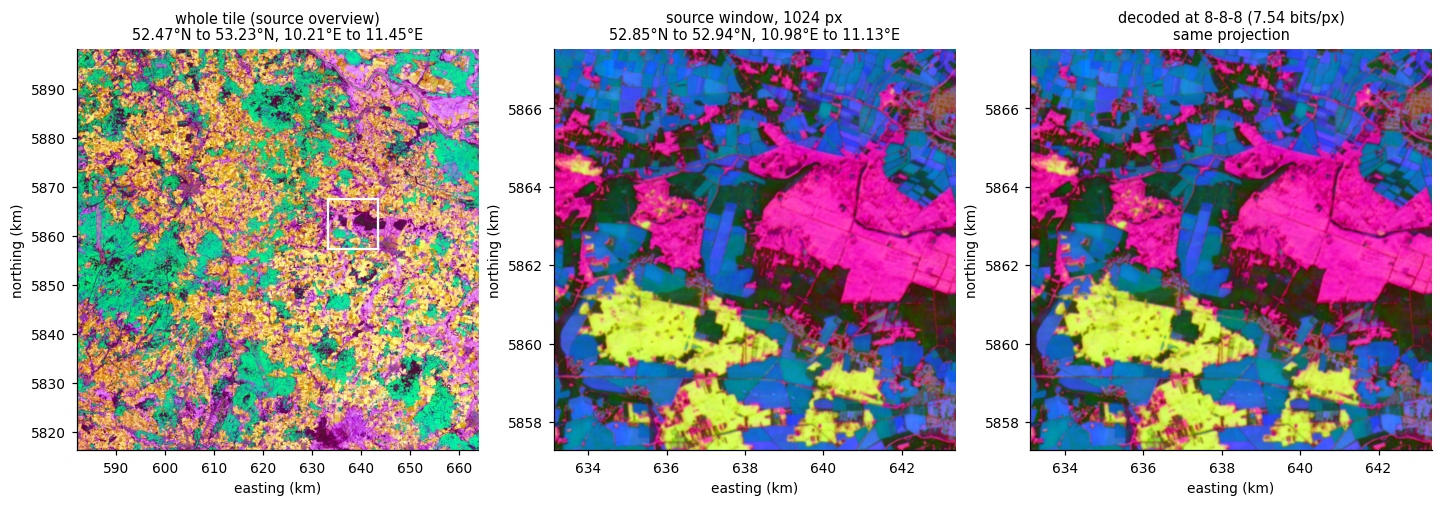

In [5]:
src = rasterio.open(source_url(TILE))
ov = src.read(out_shape=(64, 1024, 1024))                  # from the source's overviews
ov_t = src.transform * src.transform.scale(src.width / 1024, src.height / 1024)

ref = src.read(window=WINDOW)
t = time.perf_counter()
full = ds.read(window=WINDOW)                             # quality=None: full depth, 8-8-8
print(f"decoded {full.shape} {full.dtype} in {time.perf_counter() - t:.1f} s "
      f"on {getattr(ds.codec, 'device', 'cpu')}")

u_ref = unit(ref)
pca = PCARGB().fit(u_ref)
win_t = rasterio.windows.transform(WINDOW, ds.transform)

fig, ax = plt.subplots(1, 3, figsize=(13, 4.6), constrained_layout=True)
show(ax[0], PCARGB().fit(unit(ov))(unit(ov)), ov_t)
x0, y0, x1, y1 = corners(win_t, 1024, 1024)
ax[0].add_patch(Rectangle((x0 / 1e3, y0 / 1e3), (x1 - x0) / 1e3, (y1 - y0) / 1e3,
                          fill=False, ec="white", lw=1.5))
ax[0].set_title(f"whole tile (source overview)\n{lonlat(ds.crs, ds.transform, ds.height, ds.width)}")
show(ax[1], pca(u_ref), win_t)
ax[1].set_title(f"source window, 1024 px\n{lonlat(ds.crs, win_t, 1024, 1024)}")
show(ax[2], pca(unit(full)), win_t)
ax[2].set_title(f"decoded at 8-8-8 ({ds.header['rungs'][-1]['bits_px']:.2f} bits/px)\nsame projection")
plt.show()

## The rate ladder

The cell below decodes the window at every rung and scores each against
the source by per-pixel `1 - cos`. The figure shows a 384 px crop of
six rungs: the coarse tier alone (`2-0-0`, `8-0-0`), the mid tier added
(`8-4-0`, `8-8-0`) and fine levels on top (`8-8-2`, `8-8-8`), with the
error maps below on a log scale.

In [6]:
LADDER = ["2-0-0", "8-0-0", "8-4-0", "8-8-0", "8-8-2", "8-8-8"]
valid_ref = np.isfinite(u_ref[..., 0])
dec, scores = {}, []
t_all = time.perf_counter()
for r in ds.header["rungs"]:
    q = "-".join(map(str, r["tuple"]))
    a = ds.read(window=WINDOW, quality=q)
    e = err(u_ref, unit(a))[valid_ref]
    scores.append({"rung": q, "bits_px": r["bits_px"], "mean": e.mean(),
                   "p99": np.quantile(e, 0.99)})
    if q in LADDER:
        dec[q] = a
scores = pd.DataFrame(scores).set_index("rung")
print(f"23 decodes of the window in {time.perf_counter() - t_all:.1f} s")
scores.loc[LADDER].style.format({"bits_px": "{:.3f}", "mean": "{:.4f}", "p99": "{:.4f}"})

23 decodes of the window in 8.5 s


,bits_px,mean,p99
rung,,,
2-0-0,0.113,0.0528,0.2303
8-0-0,0.129,0.0388,0.1719
8-4-0,0.332,0.0152,0.0678
8-8-0,0.535,0.0113,0.0503
8-8-2,2.285,0.0061,0.0227
8-8-8,7.535,0.0031,0.0125


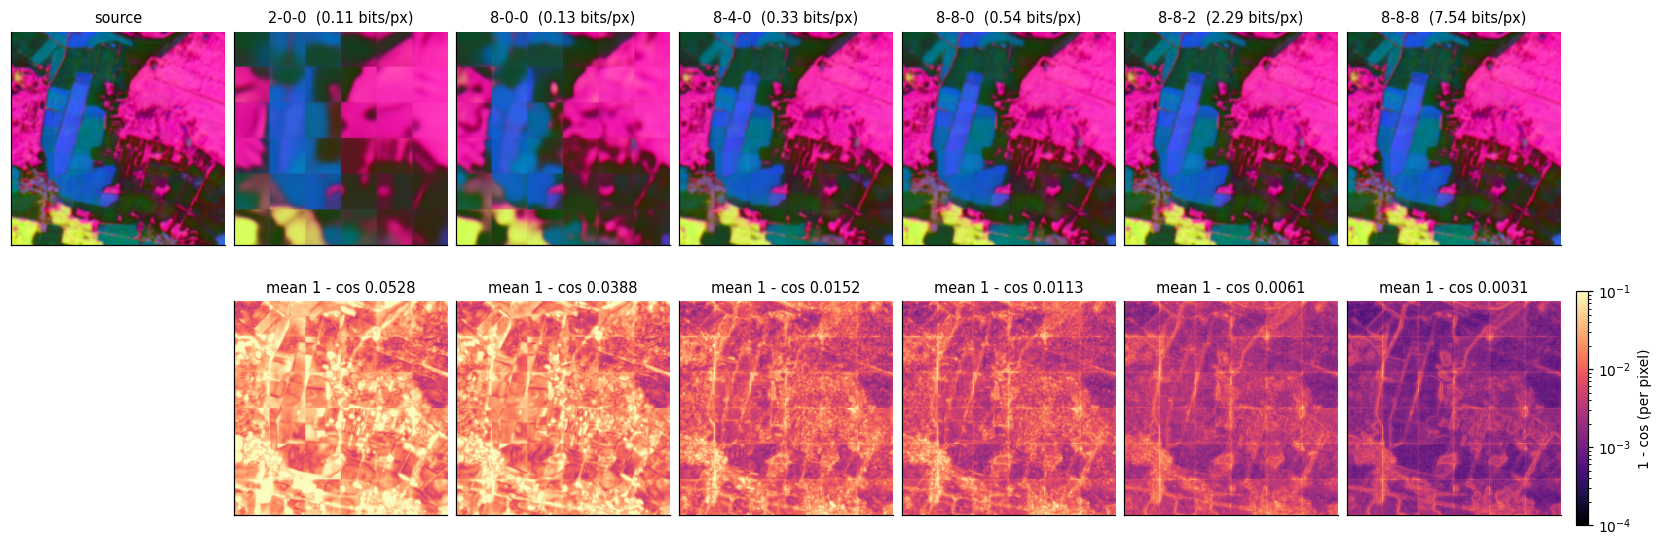

In [7]:
crop = np.s_[320:704, 320:704]          # rows and columns of the window, source order
crop_t = rasterio.windows.transform(Window(WINDOW.col_off + 320, WINDOW.row_off + 320, 384, 384),
                                    ds.transform)
fig, ax = plt.subplots(2, 7, figsize=(15, 4.9), constrained_layout=True)
show(ax[0, 0], pca(u_ref[crop]), crop_t, ticks=False)
ax[0, 0].set_title("source")
ax[1, 0].axis("off")
norm = LogNorm(1e-4, 1e-1)
for k, q in enumerate(LADDER, 1):
    u = unit(dec[q][(slice(None),) + crop])
    show(ax[0, k], pca(u), crop_t, ticks=False)
    ax[0, k].set_title(f"{q}  ({scores.loc[q, 'bits_px']:.2f} bits/px)")
    im = show(ax[1, k], np.maximum(err(u_ref[crop], u), 1e-5), crop_t, ticks=False,
              cmap="magma", norm=norm)
    ax[1, k].set_title(f"mean 1 - cos {scores.loc[q, 'mean']:.4f}")
fig.colorbar(im, ax=ax[1, :], shrink=0.9, label="1 - cos (per pixel)", pad=0.01)
plt.show()

The curve puts the 23 rungs on one axis. The blue points are measured
on this window here. The orange points cover the whole tile and come
from the file's quality column, which holds, for every 64 px window and
every rung, the mean and 99th percentile of `1 - cos` measured when the
tile was encoded; they are averaged over the tile's valid pixels and
need no decoding. Mid levels cost 208 bits per window and fine levels
3,584, which gives the two slopes.

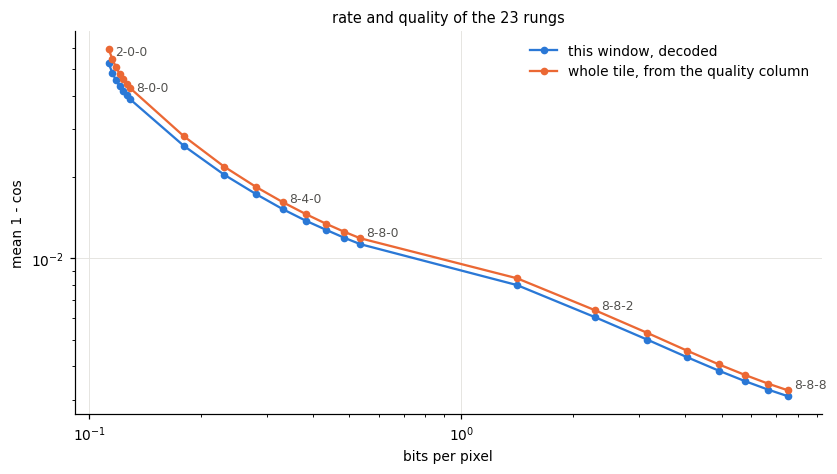

In [8]:
gh, gw = ds.height // ds.window_px, ds.width // ds.window_px
n_r = len(ds.rungs)
qc = ds.quality_codes(0, gh, 0, gw)                       # north-up window grid
mask = ds.dataset_mask() > 0
mask_n = mask[::-1] if ds.transform.e > 0 else mask
count = mask_n.reshape(gh, ds.window_px, gw, ds.window_px).sum((1, 3))
tile_mean = (quality_value(qc[..., :n_r]) * count[..., None]).sum((0, 1)) / count.sum()

fig, ax = plt.subplots(figsize=(7.5, 4.2), constrained_layout=True)
bpp = scores["bits_px"].values
ax.plot(bpp, scores["mean"], "-o", color=BLUE, ms=4, lw=1.5, label="this window, decoded")
ax.plot(bpp, tile_mean, "-o", color=ORANGE, ms=4, lw=1.5, label="whole tile, from the quality column")
for q in LADDER:
    i = list(scores.index).index(q)
    ax.annotate(q, (bpp[i], scores["mean"].iloc[i]), textcoords="offset points",
                xytext=(4, 5), fontsize=8, color=INK)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("bits per pixel"); ax.set_ylabel("mean 1 - cos")
ax.grid(True, which="major", color="#e4e3df", lw=0.6)
ax.legend()
ax.set_title("rate and quality of the 23 rungs")
plt.show()

## What reads cost

Each read below opens the file afresh, so nothing is cached, and counts
the requests and bytes fetched after the footer. The source column is
the size of the GeoTIFF blocks GDAL has to fetch for the same read: the
source is tiled in 1024 px blocks with each band stored separately, so
any read touches whole blocks of all 64 bands. The two whole-tile rows
fetch the records without decoding them.

In [9]:
def cost(fn):
    with georvq.ae.open(path, codec=ds.codec) as d:
        s0 = dict(d.reader.stats)
        fn(d)
        return d.reader.stats["requests"] - s0["requests"], d.reader.stats["bytes"] - s0["bytes"]


def src_block_bytes(rows, cols):
    return sum(int(src.get_tag_item(f"BLOCK_SIZE_{j}_{i}", "TIFF", bidx=b))
               for b in range(1, 65) for i in rows for j in cols)


bi, bj = WINDOW.row_off // 1024, WINDOW.col_off // 1024
block_src = src_block_bytes([bi], [bj])
tile_src = src_block_bytes(range(8), range(8))
px = Window(WINDOW.col_off + 500, WINDOW.row_off + 500, 1, 1)
reads = [("one pixel at 8-8-8", lambda d: d.read(window=px, quality="8-8-8"), block_src)]
for q in ["8-0-0", "8-8-0", "8-8-2", "8-8-8"]:
    reads.append((f"1024 px block at {q}", lambda d, q=q: d.read(window=WINDOW, quality=q), block_src))
for q in [(8, 0, 0), (8, 8, 0), (8, 8, 8)]:
    reads.append((f"whole tile at {'-'.join(map(str, q))}",
                  lambda d, q=q: d.reader.read(0, gh, 0, gw, depths=list(q)), tile_src))

costs = pd.DataFrame([dict(zip(("read", "requests", "bytes"), (name,) + cost(fn)), source_bytes=sb)
                      for name, fn, sb in reads]).set_index("read")
costs["source / georvq"] = (costs["source_bytes"] / costs["bytes"]).round(1)
print(f"open: 1 request, {mb(ds.reader.metadata.serialized_size + 8)} of footer "
      f"in a {mb(262144)} suffix read")
costs

open: 1 request, 0.14 MB of footer in a 0.26 MB suffix read


,requests,bytes,source_bytes,source / georvq
read,,,,
one pixel at 8-8-8,3,2851379,37534127,13.2
1024 px block at 8-0-0,1,1081379,37534127,34.7
1024 px block at 8-8-0,2,1933611,37534127,19.4
1024 px block at 8-8-2,3,2163053,37534127,17.4
1024 px block at 8-8-8,3,2851379,37534127,13.2
whole tile at 8-0-0,1,1081379,2420639947,2238.5
whole tile at 8-8-0,1,4494500,2420639947,538.6
whole tile at 8-8-8,1,63295468,2420639947,38.2


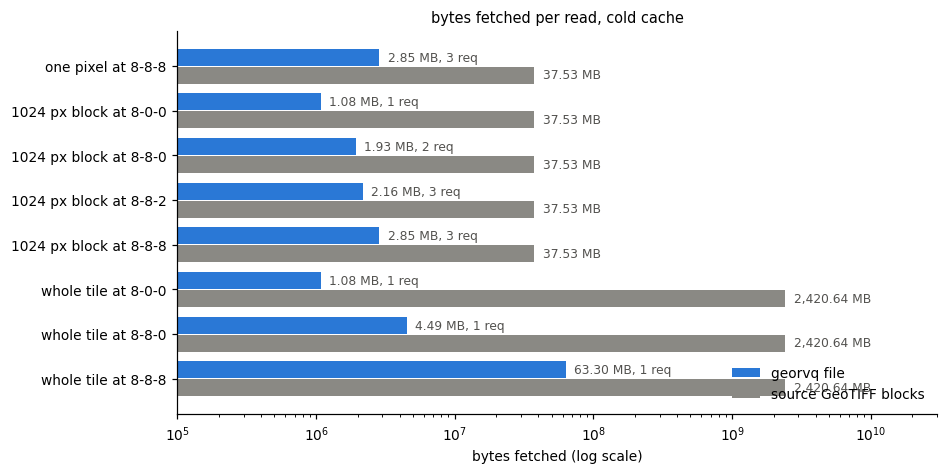

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 4.2), constrained_layout=True)
y = np.arange(len(costs))[::-1]
ax.barh(y + 0.2, costs["bytes"], height=0.38, color=BLUE, label="georvq file")
ax.barh(y - 0.2, costs["source_bytes"], height=0.38, color=GREY, label="source GeoTIFF blocks")
for yy, (n, b) in zip(y, zip(costs["requests"], costs["bytes"])):
    ax.text(b * 1.15, yy + 0.2, f"{mb(b)}, {n} req", va="center", fontsize=8, color=INK)
for yy, b in zip(y, costs["source_bytes"]):
    ax.text(b * 1.15, yy - 0.2, mb(b), va="center", fontsize=8, color=INK)
ax.set_yticks(y, costs.index)
ax.set_xscale("log"); ax.set_xlim(1e5, 3e10)
ax.set_xlabel("bytes fetched (log scale)")
ax.legend(loc="lower right")
ax.set_title("bytes fetched per read, cold cache")
plt.show()

## How long a read takes over HTTP

This section times one cold read of the 1024 px block, from
`georvq.ae.open` to the int8 array in memory, at four rungs, and the
same block read from the source tile on Source Cooperative with
rasterio and GDAL. The codec is loaded beforehand and reused, so
loading the weights is not timed.

The coded sample is not hosted next to the source, so a fair
comparison needs a stand-in. The first cell measures the latency (time
to first byte of small range requests) and the single-stream
throughput (one 16 MB range request) from this machine to Source
Cooperative. With `SIMULATE_REMOTE = True`, the coded file is then
served from a local range server that waits that latency before each
response and limits each response to that throughput. The georvq
reader's own trace records its requests, which run up to 16 at a time,
and the decode stages. The source read goes through a local forwarding
server that times each GDAL request to Source Cooperative; GDAL's
decompression is not separated from its requests and appears as gaps.
With `SIMULATE_REMOTE = False` and `DATA_ROOT` set to a URL, the same
cell reads the hosted file with no simulation.

In [11]:
import ae_demo_http

src_remote = f"{SOURCE_REMOTE}/{TILE}.tiff"
net = ae_demo_http.probe(src_remote)
print(f"latency {net['latency_s'] * 1e3:.0f} ms (median of "
      f"{', '.join(f'{v * 1e3:.0f}' for v in net['ttfb_all_s'])} ms), "
      f"throughput {net['throughput_Bps'] / 1e6:.2f} MB/s over one "
      f"{net['large_bytes'] / 1e6:.0f} MB request")

latency 751 ms (median of 205, 658, 751, 776, 2609 ms), throughput 11.55 MB/s over one 17 MB request


In [12]:
SPEED_RUNGS = ["8-0-0", "8-8-0", "8-8-2", "8-8-8"]
codec = ds.codec
servers = []
if SIMULATE_REMOTE:
    local = data_url(TILE)
    base, _, srv_sim = ae_demo_http.serve(root=os.path.dirname(local), latency=net["latency_s"],
                                          bandwidth=net["throughput_Bps"])
    servers.append(srv_sim)
    speed_url = f"{base}/{os.path.basename(local)}"
else:
    speed_url = data_url(TILE)

runs = {}
for q in SPEED_RUNGS:
    tr = Trace()
    t0 = time.perf_counter()
    with georvq.ae.open(speed_url, codec=codec, trace=tr) as d:
        a = d.read(window=WINDOW, quality=q)
        nbytes = d.reader.stats["bytes"]
    runs[f"georvq {q}"] = {"t0": t0, "t1": time.perf_counter(), "events": tr.events,
                           "bytes": nbytes}

base_s, rec_s, srv_up = ae_demo_http.serve(upstream=SOURCE_REMOTE)
servers.append(srv_up)
t0 = time.perf_counter()
with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"):
    with rasterio.open(f"{base_s}/{TILE}.tiff") as s:
        t_open = time.perf_counter()
        a_src = s.read(window=WINDOW)
t1 = time.perf_counter()
runs["source GeoTIFF"] = {"t0": t0, "t1": t1, "bytes": sum(e["bytes"] for e in rec_s.events),
                          "events": rec_s.events + [
                              {"kind": "cpu", "label": "GDAL open", "t0": t0, "t1": t_open, "bytes": 0}]}
for s_ in servers:
    s_.shutdown()
assert np.array_equal(a_src, ref)
for k, r in runs.items():
    n = sum(e["kind"] == "get" for e in r["events"])
    print(f"{k:<16} {r['t1'] - r['t0']:7.2f} s  {n:3d} requests  {mb(r['bytes'])}")

georvq 8-0-0        1.18 s    2 requests  1.34 MB
georvq 8-8-0        1.26 s    3 requests  2.20 MB
georvq 8-8-2        1.29 s    4 requests  2.43 MB
georvq 8-8-8        1.34 s    4 requests  3.11 MB
source GeoTIFF     41.68 s   67 requests  38.41 MB


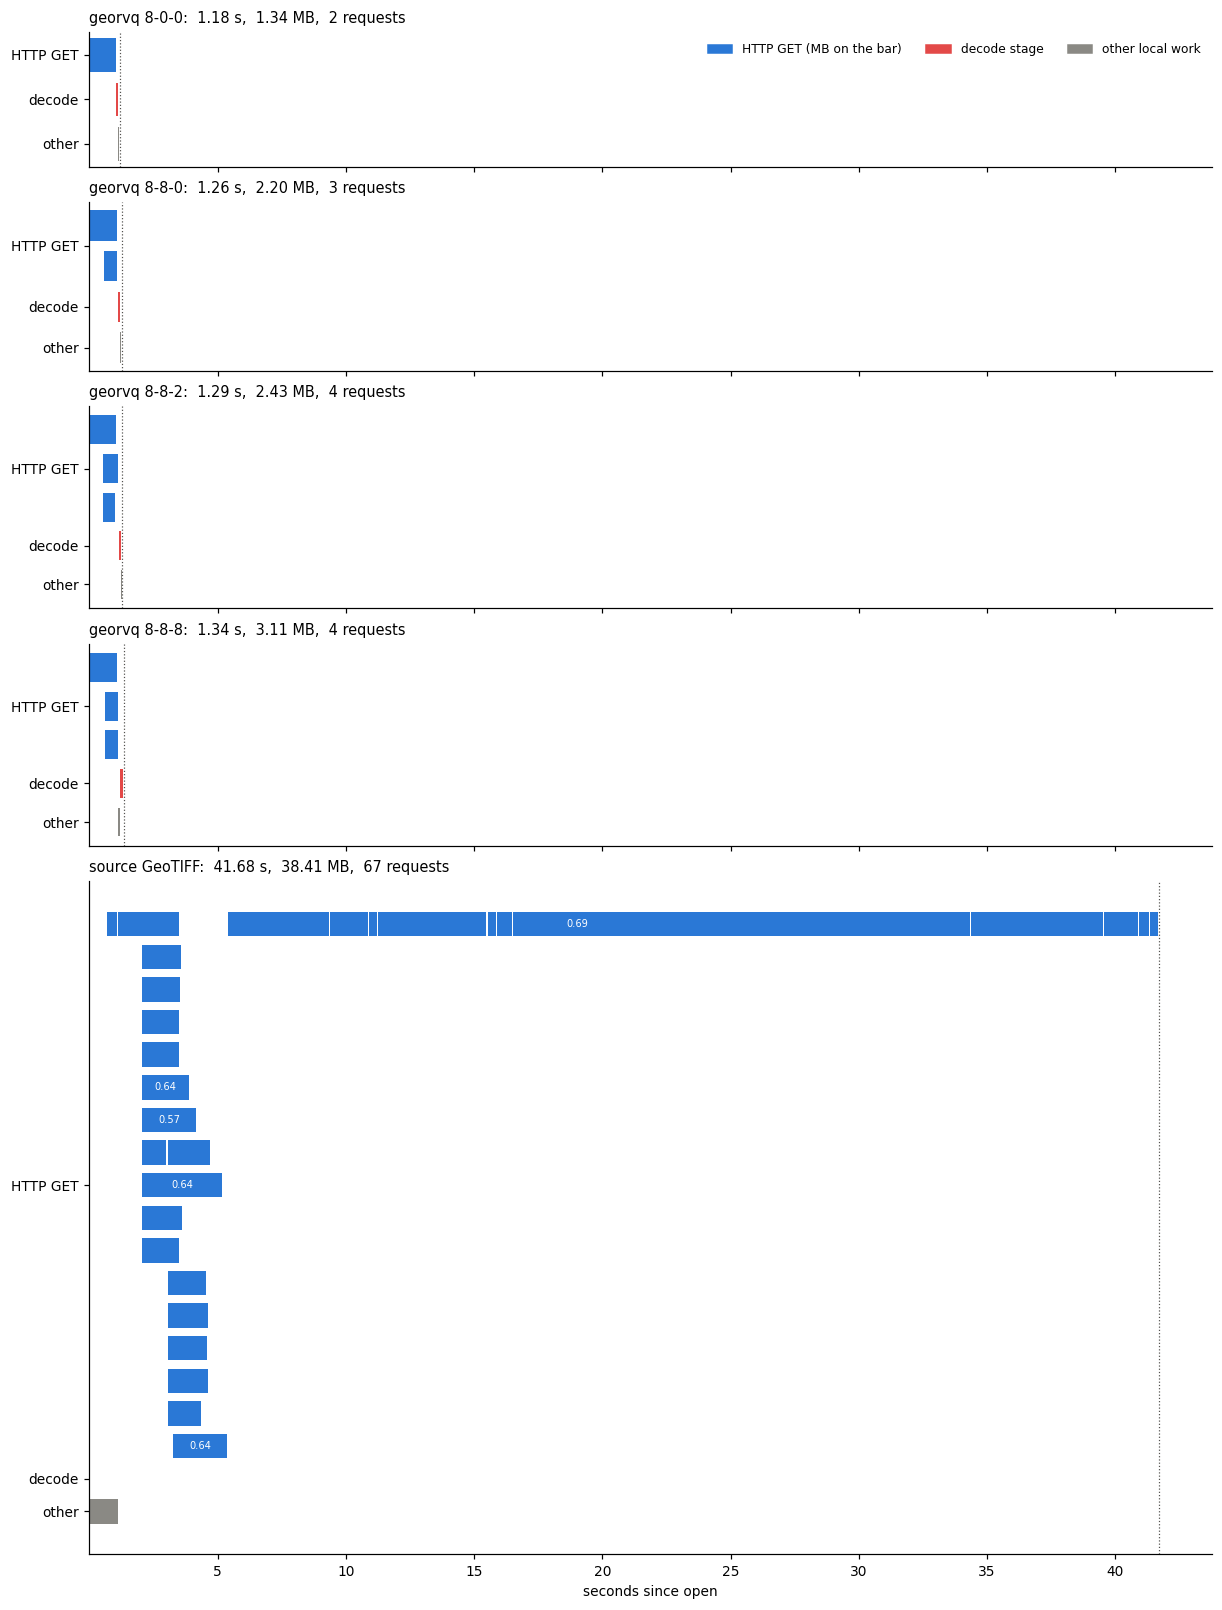

,mean channel (ms),codebook lookup (ms),decoder forward (ms),requantize (ms)
read,,,,
georvq 8-0-0,1.4,1.0,61.4,37.8
georvq 8-8-0,1.3,1.5,61.2,38.1
georvq 8-8-2,1.3,2.4,61.4,37.3
georvq 8-8-8,0.7,2.4,60.6,37.1


In [13]:
COLOURS = {"get": BLUE, "decode": RED, "cpu": GREY}


def lanes(events):
    """Greedy lane assignment so overlapping events do not cover each other."""
    ends, out = [], []
    for e in sorted(events, key=lambda e: e["t0"]):
        for i, end in enumerate(ends):
            if e["t0"] >= end:
                ends[i] = e["t1"]; out.append((i, e)); break
        else:
            ends.append(e["t1"]); out.append((len(ends) - 1, e))
    return out, len(ends)


def gantt(runs):
    groups = {k: {kind: lanes([e for e in r["events"] if e["kind"] == kind])
                  for kind in ("get", "decode", "cpu")} for k, r in runs.items()}
    heights = [sum(max(n, 1) for _, n in g.values()) + 1 for g in groups.values()]
    t_max = max(r["t1"] - r["t0"] for r in runs.values())
    fig, axes = plt.subplots(len(runs), 1, figsize=(11, 0.32 * sum(heights) + 1.4), sharex=True,
                             gridspec_kw={"height_ratios": heights}, constrained_layout=True)
    for ax, (k, r) in zip(axes, runs.items()):
        row, ticks = 0, []
        for kind in ("get", "decode", "cpu"):
            placed, n = groups[k][kind]
            for lane, e in placed:
                x0, w = e["t0"] - r["t0"], max(e["t1"] - e["t0"], 1e-3)
                ax.barh(row + lane, w, left=x0, height=0.75, color=COLOURS[kind], lw=0)
                if kind == "get" and w > 0.04 * t_max:
                    ax.text(x0 + w / 2, row + lane, mb(e["bytes"]).replace(" MB", ""), ha="center",
                            va="center", fontsize=6.5, color="white")
            ticks.append((row + (max(n, 1) - 1) / 2, {"get": "HTTP GET", "decode": "decode",
                                                        "cpu": "other"}[kind]))
            row += max(n, 1)
        ax.set_yticks([t for t, _ in ticks], [l for _, l in ticks])
        ax.invert_yaxis()
        ax.set_title(f"{k}:  {r['t1'] - r['t0']:.2f} s,  {mb(r['bytes'])},  "
                     f"{sum(e['kind'] == 'get' for e in r['events'])} requests", loc="left")
        ax.axvline(r["t1"] - r["t0"], color=INK, lw=0.8, ls=":")
    axes[-1].set_xlabel("seconds since open")
    axes[0].legend(handles=[Rectangle((0, 0), 1, 1, color=c) for c in COLOURS.values()],
                   labels=["HTTP GET (MB on the bar)", "decode stage", "other local work"],
                   loc="upper right", ncol=3, fontsize=8)
    plt.show()


gantt(runs)

stages = pd.DataFrame([{**{"read": k}, **{lab: sum(e["t1"] - e["t0"] for e in r["events"]
                                               if e["label"] == lab)
                                           for lab in ("mean channel", "codebook lookup",
                                                       "decoder forward", "requantize")}}
                       for k, r in runs.items() if k.startswith("georvq")]).set_index("read")
(stages * 1e3).round(1).rename(columns=lambda c: c + " (ms)")

At 1024 px the four rungs take almost the same time, because the fixed
cost of a read dominates: opening the file is one 256 KiB request for
the footer, and each tier read is another round trip, so at about 0.7 s
of latency the difference between 1.3 MB and 3.1 MB is hidden. Small
random reads are limited by the number of requests rather than by their
size, which is why the reader fetches the footer once and merges nearby
ranges into one request.

Reading a quarter of the tile (4096 px, one mid chunk and 16 fine
chunks) shows the other side. The bytes now differ by more than ten
times between 8-0-0 and 8-8-8, so the time spent fetching follows the
rung. The decoder, however, runs at full resolution whatever the rung,
so the decode time is the same at every rung and grows only with the
area read. The rung therefore decides how many bytes are moved and
stored, and on a GPU it changes the total time only where the link is
slow compared with the decoder.

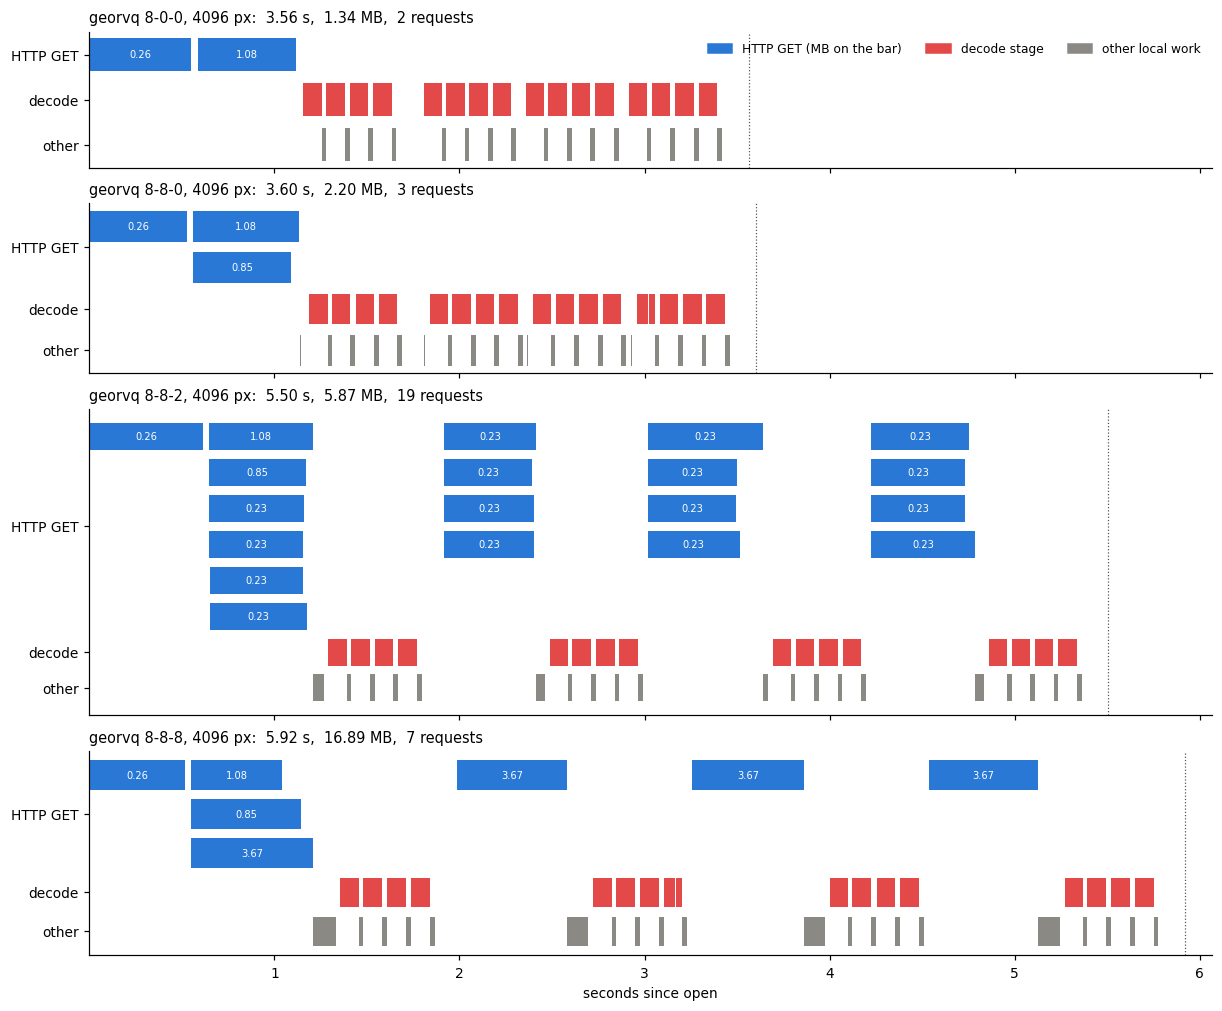

,MB,requests,fetch (s),decode (s),total (s)
read,,,,,
georvq 8-0-0,1.34,2,1.02,0.10,1.18
georvq 8-8-0,2.20,3,1.09,0.10,1.26
georvq 8-8-2,2.43,4,1.10,0.10,1.29
georvq 8-8-8,3.11,4,1.13,0.10,1.34
"georvq 8-0-0, 4096 px",1.34,2,1.08,1.59,3.56
"georvq 8-8-0, 4096 px",2.20,3,1.10,1.60,3.60
"georvq 8-8-2, 4096 px",5.87,19,2.86,1.60,5.50
"georvq 8-8-8, 4096 px",16.89,7,2.96,1.62,5.92


In [14]:
WIDE = Window(col_off=4096, row_off=0, width=4096, height=4096)


def spans(events, kind):
    """Wall-clock time covered by events of one kind (overlaps counted once)."""
    t, end = 0.0, -1e18
    for e in sorted((e for e in events if e["kind"] == kind), key=lambda e: e["t0"]):
        t0 = max(e["t0"], end)
        if e["t1"] > t0:
            t += e["t1"] - t0
        end = max(end, e["t1"])
    return t


wide = {}
for q in SPEED_RUNGS:
    tr = Trace()
    t0 = time.perf_counter()
    with georvq.ae.open(speed_url, codec=codec, trace=tr) as d:
        d.read(window=WIDE, quality=q)
        nbytes = d.reader.stats["bytes"]
    wide[f"georvq {q}, 4096 px"] = {"t0": t0, "t1": time.perf_counter(), "events": tr.events,
                                    "bytes": nbytes}
gantt(wide)
pd.DataFrame([{"read": k, "MB": round(r["bytes"] / 1e6, 2),
               "requests": sum(e["kind"] == "get" for e in r["events"]),
               "fetch (s)": round(spans(r["events"], "get"), 2),
               "decode (s)": round(spans(r["events"], "decode"), 2),
               "total (s)": round(r["t1"] - r["t0"], 2)}
              for k, r in {**{k: v for k, v in runs.items() if k.startswith("georvq")}, **wide}.items()]
             ).set_index("read")

## Reading to a quality bound

Instead of a rung, `read` accepts a bound on a quality statistic, such
as `quality="p99<=0.02"`. The reader looks up each window's measured
errors in the quality column and decodes every window at the cheapest
rung that meets the bound, or at full depth where none does. The map
shows the rung chosen for each window of the tile. Within one read the
reader fetches each tier at the deepest level any window in the read
needs, so the bytes fetched sit between the ideal per-window cost and
the full-depth cost.

whole tile at p99<=0.02: 29.7 MB of records chosen per window, against 63.2 MB at 8-8-8
this block: 3.61 MB in 4 requests at p99<=0.02, against 2.85 MB at 8-8-8
windows of the block meeting the bound when decoded here: 98.8% (worst p99 0.0219)


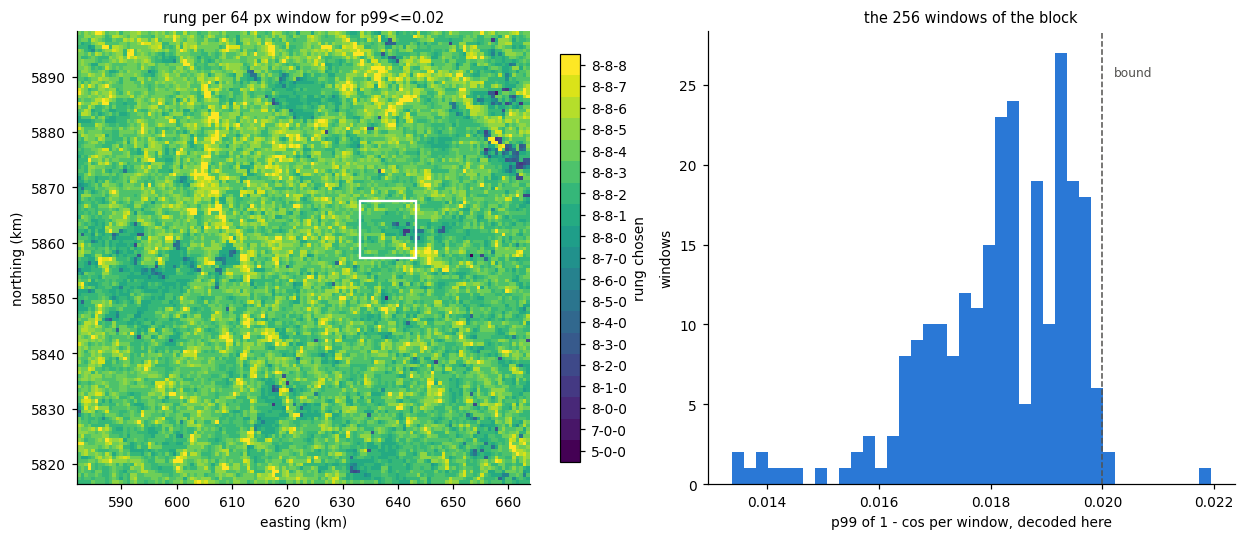

In [15]:
BOUND = "p99<=0.02"
rmap = ds.window_rungs(BOUND)                               # whole tile, north-up window grid
bits = np.array([r["bits_window"] for r in ds.header["rungs"]])
names = ["-".join(map(str, r)) for r in ds.rungs]
used = np.unique(rmap)

d_q = cost(lambda d: d.read(window=WINDOW, quality=BOUND))
a_q = ds.read(window=WINDOW, quality=BOUND)
e_q = err(u_ref, unit(a_q))
W = ds.window_px
e_w = np.where(valid_ref, e_q, np.nan).reshape(16, W, 16, W).transpose(0, 2, 1, 3).reshape(16, 16, -1)
p99_w = np.nanquantile(e_w, 0.99, axis=-1)

print(f"whole tile at {BOUND}: {bits[rmap].sum() / 8 / 1e6:.1f} MB of records chosen per window, "
      f"against {rmap.size * bits[-1] / 8 / 1e6:.1f} MB at 8-8-8")
print(f"this block: {mb(d_q[1])} in {d_q[0]} requests at {BOUND}, "
      f"against {mb(costs.loc['1024 px block at 8-8-8', 'bytes'])} at 8-8-8")
print(f"windows of the block meeting the bound when decoded here: "
      f"{(p99_w <= 0.02).mean():.1%} (worst p99 {np.nanmax(p99_w):.4f})")

cmap = plt.get_cmap("viridis", len(used))
lut = np.zeros(len(ds.rungs), int); lut[used] = np.arange(len(used))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True,
                       gridspec_kw={"width_ratios": [1.15, 1]})
x0, y0, x1, y1 = corners(ds.transform, ds.height, ds.width)
im = ax[0].imshow(lut[rmap], cmap=cmap, vmin=-0.5, vmax=len(used) - 0.5,
                  extent=[x0 / 1e3, x1 / 1e3, y0 / 1e3, y1 / 1e3], interpolation="nearest")
cb = fig.colorbar(im, ax=ax[0], ticks=np.arange(len(used)), shrink=0.9)
cb.ax.set_yticklabels([names[i] for i in used]); cb.set_label("rung chosen")
bx0, by0, bx1, by1 = corners(win_t, 1024, 1024)
ax[0].add_patch(Rectangle((bx0 / 1e3, by0 / 1e3), (bx1 - bx0) / 1e3, (by1 - by0) / 1e3,
                          fill=False, ec="white", lw=1.5))
ax[0].set_xlabel("easting (km)"); ax[0].set_ylabel("northing (km)")
ax[0].set_title(f"rung per 64 px window for {BOUND}")
ax[1].hist(p99_w.ravel(), bins=40, color=BLUE)
ax[1].axvline(0.02, color=INK, ls="--", lw=1)
ax[1].text(0.0202, ax[1].get_ylim()[1] * 0.9, "bound", color=INK, fontsize=8)
ax[1].set_xlabel("p99 of 1 - cos per window, decoded here")
ax[1].set_ylabel("windows")
ax[1].set_title("the 256 windows of the block")
plt.show()

## Similarity search and clustering

Two common uses of the embeddings, run on the source window and on
reconstructions at four rungs. The search takes the embedding of one
pixel (marked) and maps its cosine similarity to every pixel of the
window; each product is queried with its own pixel, as a user holding
only that product would. The clustering fits k-means with 8 clusters
on the source and assigns the pixels of every product to the same
centroids. The table reports the correlation of each similarity map
with the source's, the share of the source's top 1% most similar
pixels that are also in the reconstruction's top 1%, and the share of
pixels assigned to the same cluster.

In [16]:
from sklearn.cluster import KMeans

QUERY = (612, 300)                       # row, column in the window
SHOW = ["8-0-0", "8-8-0", "8-8-2", "8-8-8"]
prods = {"source": u_ref} | {q: unit(dec[q]) for q in SHOW}

X = u_ref[valid_ref]
km = KMeans(8, n_init=4, random_state=0).fit(
    X[np.random.default_rng(0).choice(len(X), 50_000, replace=False)])
sims, labels, rows = {}, {}, []
for k, u in prods.items():
    s = (np.nan_to_num(u) @ u[QUERY]).astype(np.float32)
    s[~valid_ref] = np.nan
    lab = np.full(valid_ref.shape, -1)
    lab[valid_ref] = km.predict(np.nan_to_num(u[valid_ref]))
    sims[k], labels[k] = s, lab
top = lambda s: s >= np.nanquantile(s, 0.99)
for k in SHOW:
    rows.append({"rung": k,
                 "similarity r": np.corrcoef(sims["source"][valid_ref], sims[k][valid_ref])[0, 1],
                 "top 1% recall": (top(sims["source"]) & top(sims[k])).sum() / top(sims["source"]).sum(),
                 "same cluster": (labels[k] == labels["source"])[valid_ref].mean()})
pd.DataFrame(rows).set_index("rung").style.format("{:.3f}")

,similarity r,top 1% recall,same cluster
rung,,,
8-0-0,0.860,0.220,0.776
8-8-0,0.966,0.514,0.921
8-8-2,0.963,0.613,0.948
8-8-8,0.980,0.673,0.958


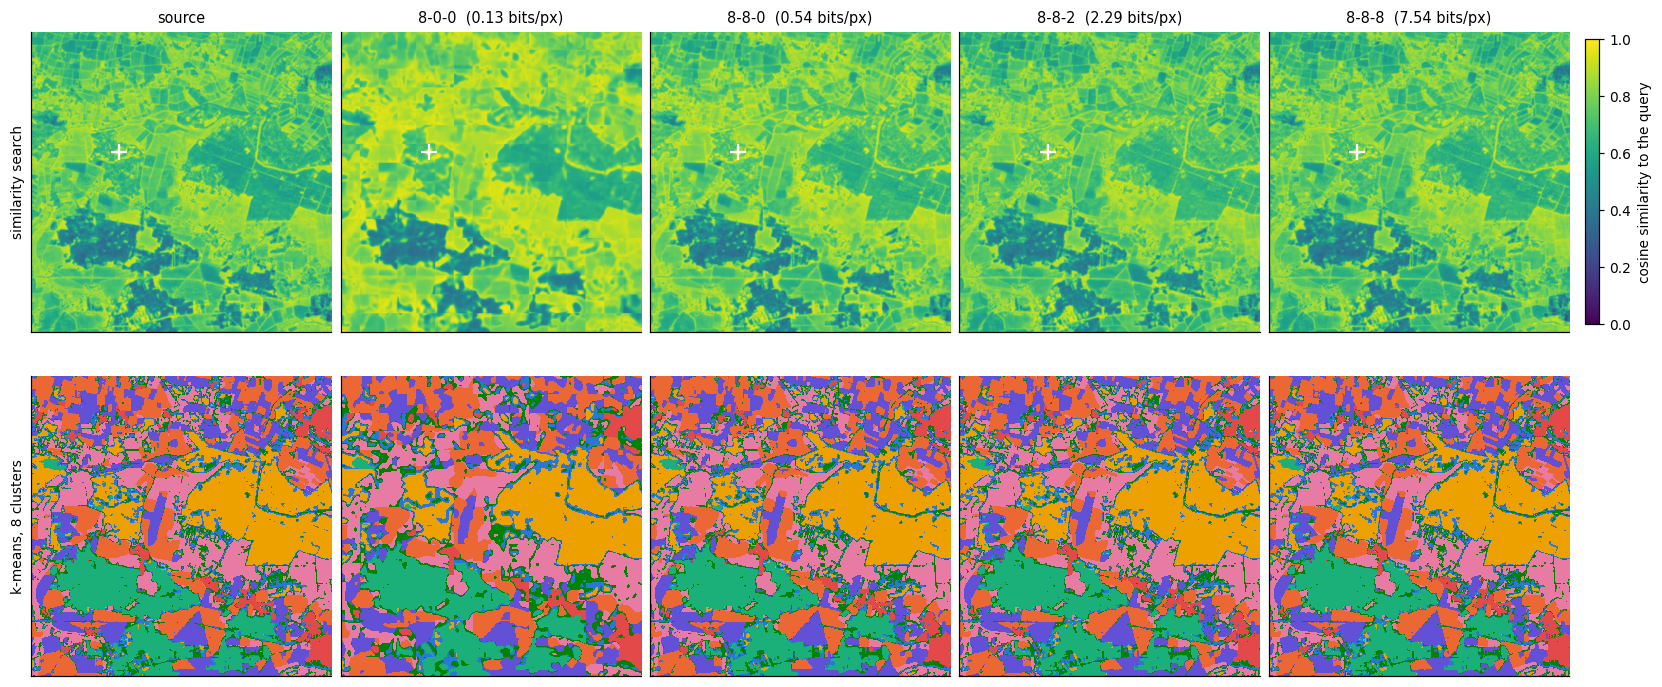

In [17]:
fig, ax = plt.subplots(2, 5, figsize=(15, 6.3), constrained_layout=True)
qx, qy = win_t * (QUERY[1] + 0.5, QUERY[0] + 0.5)
ccmap = ListedColormap([BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED])
for j, (k, s) in enumerate(sims.items()):
    im = show(ax[0, j], s, win_t, ticks=False, cmap="viridis", vmin=0, vmax=1)
    ax[0, j].plot(qx / 1e3, qy / 1e3, "+", color="white", ms=10, mew=1.5)
    ax[0, j].set_title(k if k == "source" else f"{k}  ({scores.loc[k, 'bits_px']:.2f} bits/px)")
    show(ax[1, j], np.ma.masked_less(labels[k], 0), win_t, ticks=False, cmap=ccmap,
         vmin=-0.5, vmax=7.5, interpolation="nearest")
fig.colorbar(im, ax=ax[0, :], shrink=0.85, pad=0.01, label="cosine similarity to the query")
ax[0, 0].set_ylabel("similarity search"); ax[1, 0].set_ylabel("k-means, 8 clusters")
plt.show()

## Nodata and partial tiles

Coastal and border tiles are partly nodata (all 64 bands at -128). The
file stores the tile's validity mask once, losslessly, and the reader
writes -128 back wherever it is unset, so nodata comes back exactly. A
window with no valid pixel is not coded, and a chunk with none is
stored empty, which makes partial tiles smaller. The block shown is the
one whose valid share is closest to one half. In the AlphaEarth tiles
nodata starts offshore, so the valid part of such a block is open sea,
where the embeddings are close to constant. The colours are therefore
fitted on the whole tile, which also holds land; fitted on the block
alone they would stretch the small variation over the sea, down to the
int8 steps of the source, across the full colour range.

valid pixels 50.5%; file 42.21 MB (the fully valid tile above: 64.19 MB); source 821.29 MB
empty chunks per kind: {'base': 0, 'mid': 0, 'fine': 24, 'quality': 0}
block (2, 2), 51.5% valid: nodata pixels 508,168 in the source, 508,168 decoded, 0 disagreeing
reading an all-nodata block at 8-8-8: 0 requests, 0.00 MB


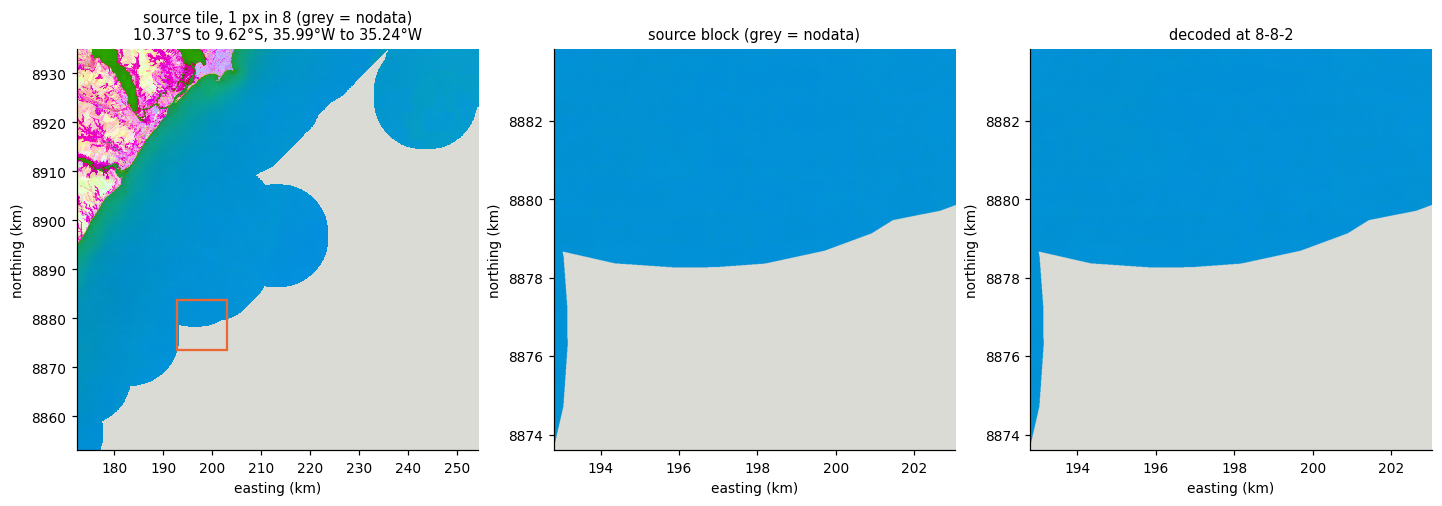

In [18]:
cpath = data_url(COAST_TILE)
cds = georvq.ae.open(cpath, codec=ds.codec)
csrc = rasterio.open(source_url(COAST_TILE))
cmask = cds.dataset_mask() > 0                               # source row order
frac = cmask.reshape(8, 1024, 8, 1024).mean((1, 3))
ci, cj = np.unravel_index(np.abs(frac - 0.5).argmin(), frac.shape)
CWIN = Window(cj * 1024, ci * 1024, 1024, 1024)
c_ref, c_dec = csrc.read(window=CWIN), cds.read(window=CWIN, quality="8-8-2")
nod_ref, nod_dec = (c_ref == -128).all(0), (c_dec == -128).all(0)
empty = {g["kind"]: len(g.get("empty_chunks", [])) for g in cds.header["layout"]["groups"]}
ei, ej = np.argwhere(frac == 0)[0]
with georvq.ae.open(cpath, codec=ds.codec) as d:
    s0 = dict(d.reader.stats)
    d.read(window=Window(ej * 1024, ei * 1024, 1024, 1024), quality="8-8-8")
    empty_read = (d.reader.stats["requests"] - s0["requests"], d.reader.stats["bytes"] - s0["bytes"])

print(f"valid pixels {cmask.mean():.1%}; file {mb(cds.reader.size)} "
      f"(the fully valid tile above: {mb(ds.reader.size)}); source {mb(size_of(source_url(COAST_TILE)))}")
print(f"empty chunks per kind: {empty}")
print(f"block ({ci}, {cj}), {frac[ci, cj]:.1%} valid: nodata pixels {nod_ref.sum():,} in the source, "
      f"{nod_dec.sum():,} decoded, {(nod_ref != nod_dec).sum()} disagreeing")
print(f"reading an all-nodata block at 8-8-8: {empty_read[0]} requests, {mb(empty_read[1])}")

cu = unit(c_ref)
c_over = csrc.read(out_shape=(csrc.count, 1024, 1024), resampling=Resampling.nearest)
cu_over = unit(c_over)
cp = PCARGB().fit(cu_over)                                   # colours from the whole tile
cwin_t = rasterio.windows.transform(CWIN, cds.transform)
fig, ax = plt.subplots(1, 3, figsize=(13, 4.6), constrained_layout=True)
show(ax[0], cp(cu_over), cds.transform * cds.transform.scale(8, 8), interpolation="nearest")
x0, y0, x1, y1 = corners(cwin_t, 1024, 1024)
ax[0].add_patch(Rectangle((x0 / 1e3, y0 / 1e3), (x1 - x0) / 1e3, (y1 - y0) / 1e3,
                          fill=False, ec=ORANGE, lw=1.5))
ax[0].set_title(f"source tile, 1 px in 8 (grey = nodata)\n{lonlat(cds.crs, cds.transform, cds.height, cds.width)}")
show(ax[1], cp(cu), cwin_t); ax[1].set_title("source block (grey = nodata)")
show(ax[2], cp(unit(c_dec)), cwin_t); ax[2].set_title("decoded at 8-8-2")
plt.show()

## The tile index

`aef_georvq_index.parquet` has one row per coded file: the source
index's row for the tile (year, UTM zone, bounds in UTM and WGS84,
footprint), the file's path, its codec ids, its size, and the bytes a
whole-tile read fetches at each rung. It is GeoParquet, so pyarrow,
GeoPandas or DuckDB can query it without opening the coded files.

6 tiles; columns: fid, crs, path, source_path, year, utm_zone, utm_west, utm_south, utm_east, utm_north, wgs84_west, wgs84_south, wgs84_east, wgs84_north, geom, geom_bbox, location, bitstream_id, decoder_id, file_bytes, footer_bytes, quality_bytes, rungs
in the Europe box: ['annual/2025/32N/xh72hhha3ih6mroc7-0000008192-0000008192.georvq.parquet']
duckdb is not installed; the same query works with read_parquet() in DuckDB


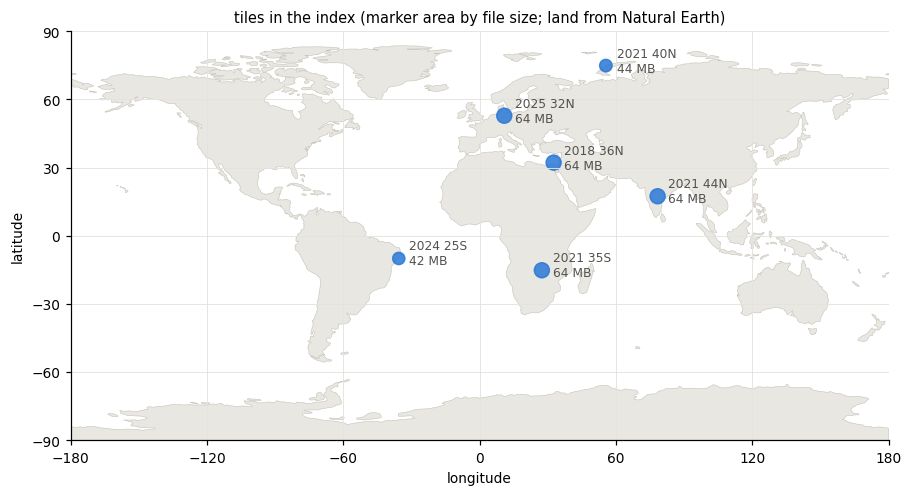

,year,zone,tile,lon,lat,file MB,8-8-0 MB
0,2021,35S,xawei966i326mixy3-0000008192-0000000000,27.38,-15.19,64.19,4.51
1,2024,25S,xny2ld0nqj92sstbu-0000000000-0000000000,-35.62,-9.99,42.21,4.54
2,2021,44N,x21yfwngg902u0lsh-0000008192-0000000000,78.35,17.39,64.21,4.53
3,2021,40N,xtuw00yqbjn5szkgd-0000008192-0000008192,55.56,74.91,44.04,4.54
4,2018,36N,x145gbb3orzpkjlqv-0000008192-0000008192,32.56,32.21,64.19,4.51
5,2025,32N,xh72hhha3ih6mroc7-0000008192-0000008192,10.83,52.85,64.19,4.51


In [19]:
import io
import pyarrow.parquet as pq
import pyarrow.compute as pc

idx_path = f"{DATA_ROOT}/aef_georvq_index.parquet"
if idx_path.startswith(("http://", "https://")):
    idx_path = io.BytesIO(urllib.request.urlopen(idx_path).read())
idx = pq.read_table(idx_path)
print(f"{idx.num_rows} tiles; columns: {', '.join(idx.column_names)}")

def at(rungs, name):
    return next(r["bytes"] for r in rungs if r["rung"] == name)

tiles = pd.DataFrame({
    "year": idx["year"].to_pylist(), "zone": idx["utm_zone"].to_pylist(),
    "tile": [p.rsplit("/", 1)[-1].split(".")[0] for p in idx["path"].to_pylist()],
    "lon": [(a + b) / 2 for a, b in zip(idx["wgs84_west"].to_pylist(), idx["wgs84_east"].to_pylist())],
    "lat": [(a + b) / 2 for a, b in zip(idx["wgs84_south"].to_pylist(), idx["wgs84_north"].to_pylist())],
    "file MB": [b / 1e6 for b in idx["file_bytes"].to_pylist()],
    "8-8-0 MB": [at(r, "8-8-0") / 1e6 for r in idx["rungs"].to_pylist()]})

# tiles whose WGS84 bounds intersect a box over Europe
box = dict(west=-10, south=35, east=30, north=70)
sel = idx.filter(pc.and_(pc.and_(pc.greater(idx["wgs84_east"], box["west"]),
                                 pc.less(idx["wgs84_west"], box["east"])),
                         pc.and_(pc.greater(idx["wgs84_north"], box["south"]),
                                 pc.less(idx["wgs84_south"], box["north"]))))
print(f"in the Europe box: {sel['path'].to_pylist()}")
try:
    import duckdb
    print(duckdb.sql(f"select year, utm_zone, file_bytes from read_parquet('{idx_path}') "
                     "order by file_bytes").df())
except ImportError:
    print("duckdb is not installed; the same query works with read_parquet() in DuckDB")

fig, ax = plt.subplots(figsize=(9, 4.4), constrained_layout=True)
try:
    import geopandas as gpd
    land = gpd.read_file("https://naciscdn.org/naturalearth/110m/physical/ne_110m_land.zip")
    land.plot(ax=ax, color="#e9e7e1", edgecolor="#c9c6bd", lw=0.4, zorder=0)
except Exception as e:                       # no geopandas or no network: points only
    print(f"no basemap ({type(e).__name__})")
ax.scatter(tiles["lon"], tiles["lat"], s=tiles["file MB"] * 1.5, color=BLUE, alpha=0.85)
for _, t in tiles.iterrows():
    ax.annotate(f"{t['year']} {t['zone']}\n{t['file MB']:.0f} MB", (t["lon"], t["lat"]),
                textcoords="offset points", xytext=(7, -4), fontsize=8, color=INK)
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90)
ax.set_xticks(range(-180, 181, 60)); ax.set_yticks(range(-90, 91, 30))
ax.grid(True, color="#e4e3df", lw=0.6, zorder=-1)
ax.set_aspect("equal")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("tiles in the index (marker area by file size; land from Natural Earth)")
plt.show()
tiles.round(2)

## Writing a GeoTIFF, and decoding without torch

`ds.profile` is the source's GeoTIFF profile (CRS, transform, block
size, compression, band descriptions in `ds.descriptions`), so a
decoded window can be written as a GeoTIFF as below. For a whole tile,
the command line does the same in 1024-row strips:

    python -m georvq.ae.v2 reconstruct FILE.georvq.parquet out.tif --quality 8-8-2
    python -m georvq.ae.v2 decode FILE.georvq.parquet out.npy --window 4096,5120,1024,1024 --quality 8-8-2

`backend="onnx"` decodes with onnxruntime and numpy from the ONNX
export in the bundle, without torch. It decodes in fp32. On CUDA the
torch backend decodes in bf16 by default, so the comparison below is
made against both the bf16 decode used above and an fp32 torch decode
(`bf16=False`).

In [20]:
out = os.path.join(tempfile.mkdtemp(), "window_8-8-2.tif")
prof = dict(ds.profile, width=WINDOW.width, height=WINDOW.height, transform=win_t)
with rasterio.open(out, "w", **prof) as dst:
    dst.write(dec["8-8-2"])
    dst.update_tags(**ds.tags())
    for b, desc in enumerate(ds.descriptions, 1):
        if desc:
            dst.set_band_description(b, desc)
with rasterio.open(out) as chk:
    print(f"{out}: {chk.width} x {chk.height}, {chk.count} bands, {chk.crs.to_string()}, "
          f"{chk.profile.get('compress')}, {mb(os.path.getsize(out))}; "
          f"identical to the array: {np.array_equal(chk.read(), dec['8-8-2'])}")

t = time.perf_counter()
with georvq.ae.open(path, backend="onnx") as dx:
    a_onnx = dx.read(window=WINDOW, quality="8-8-2")
t_onnx = time.perf_counter() - t
a_torch = dec["8-8-2"]
with georvq.ae.open(path, bf16=False) as d32:
    a_fp32 = d32.read(window=WINDOW, quality="8-8-2")
print(f"onnx backend, CPU: {t_onnx:.1f} s including loading the graphs")
for name, a in [("torch bf16", a_torch), ("torch fp32", a_fp32)]:
    diff = np.abs(a_onnx.astype(int) - a.astype(int))
    print(f"onnx against {name}: {(diff == 0).mean():.4%} of values equal, "
          f"largest difference {diff.max()} step(s)")
print(f"mean 1 - cos against the source: onnx {err(u_ref, unit(a_onnx))[valid_ref].mean():.5f}, "
      f"torch bf16 {err(u_ref, unit(a_torch))[valid_ref].mean():.5f}, "
      f"torch fp32 {err(u_ref, unit(a_fp32))[valid_ref].mean():.5f}")

/tmp/tmpbgicwth1/window_8-8-2.tif: 1024 x 1024, 64 bands, EPSG:32632, zstd, 31.91 MB; identical to the array: True


onnx backend, CPU: 8.1 s including loading the graphs


onnx against torch bf16: 84.3326% of values equal, largest difference 20 step(s)


onnx against torch fp32: 98.9781% of values equal, largest difference 4 step(s)


mean 1 - cos against the source: onnx 0.00606, torch bf16 0.00606, torch fp32 0.00606
